In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Task 1

In [2]:
np.random.seed(42)
n = 1500

loans = pd.DataFrame({
    'age': np.random.randint(21, 61, n),
    'monthly_income_inr': np.random.randint(15000, 150001, n),
    'loan_amount_inr': np.random.randint(50000, 800001, n),
    'tenure_months': np.random.choice([12, 24, 36, 48, 60], n),
    'employment': np.random.choice(['Salaried', 'Self-employed', 'Business'], n),
    'city_tier': np.random.randint(1, 4, n),
    'credit_score': np.random.randint(550, 851, n)
})

default_prob = 0.05 + 0.15 * (loans['credit_score'] < 650) + 0.10 * (loans['loan_amount_inr'] > 10 * loans['monthly_income_inr'])
loans['defaulted'] = (np.random.rand(n) < default_prob).astype(int)

loans.to_csv('loan_applications.csv', index=False)
print(loans.shape)
print(loans.head())

(1500, 8)
   age  monthly_income_inr  loan_amount_inr  tenure_months     employment  \
0   59               44241           608158             24       Salaried   
1   49               26745           677835             60       Salaried   
2   35               41029            99067             36       Business   
3   28              138395           162217             60  Self-employed   
4   41              104186           468184             60  Self-employed   

   city_tier  credit_score  defaulted  
0          1           598          1  
1          1           660          1  
2          3           768          0  
3          1           606          0  
4          1           832          0  


# Task 2

               age  monthly_income_inr  loan_amount_inr  tenure_months  \
count  1500.000000         1500.000000      1500.000000     1500.00000   
mean     41.108667        81190.732667    427714.744000       36.08800   
std      11.681774        38758.525857    209512.714391       16.92215   
min      21.000000        15138.000000     50917.000000       12.00000   
25%      31.000000        46539.000000    254498.500000       24.00000   
50%      42.000000        80689.000000    434476.500000       36.00000   
75%      51.250000       113702.750000    597282.500000       48.00000   
max      60.000000       149832.000000    799450.000000       60.00000   

       credit_score    city_tier  
count   1500.000000  1500.000000  
mean     701.506000     1.992000  
std       86.882586     0.807695  
min      550.000000     1.000000  
25%      625.000000     1.000000  
50%      703.000000     2.000000  
75%      777.000000     3.000000  
max      850.000000     3.000000  
employment
Self-em

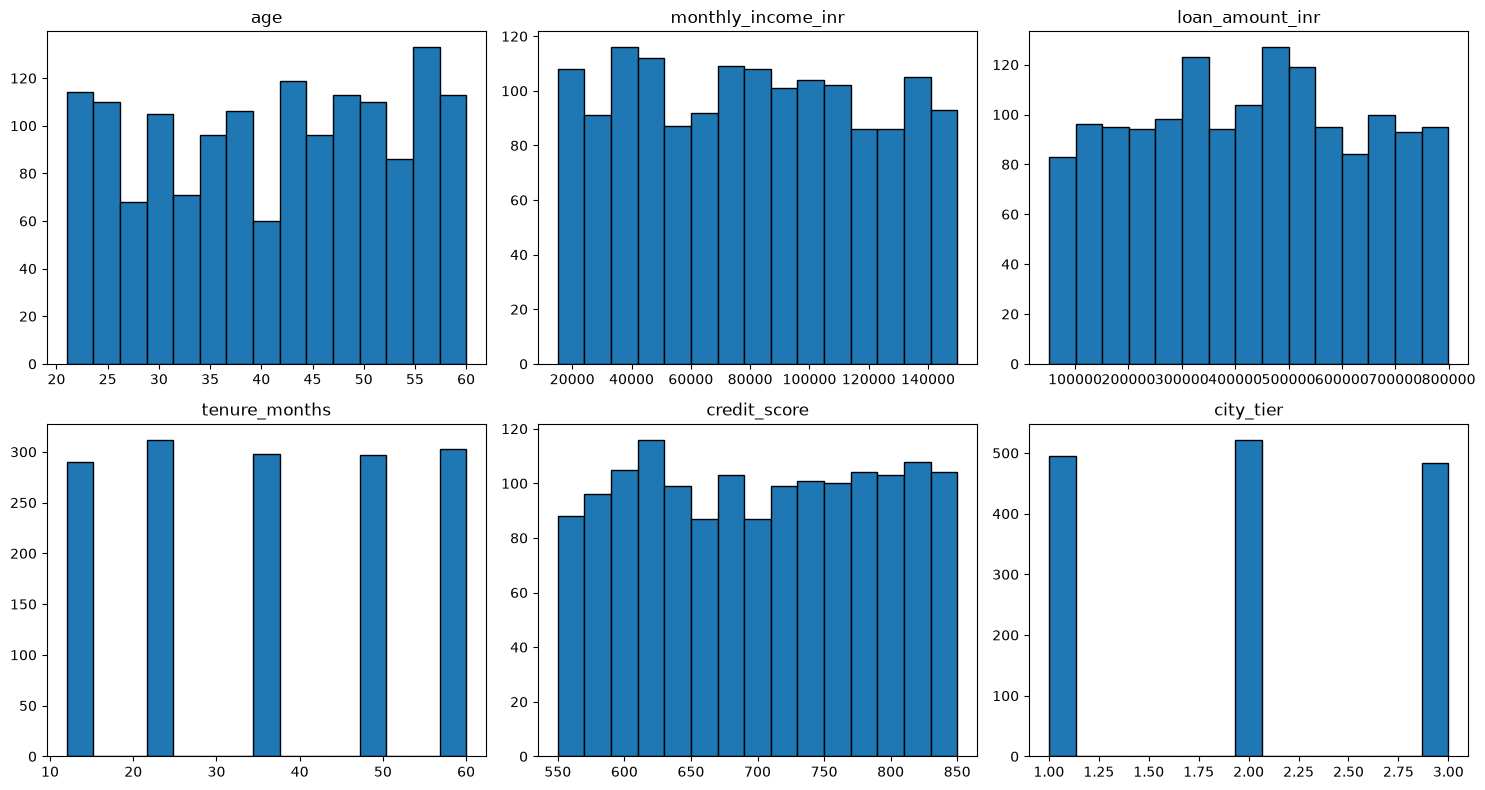

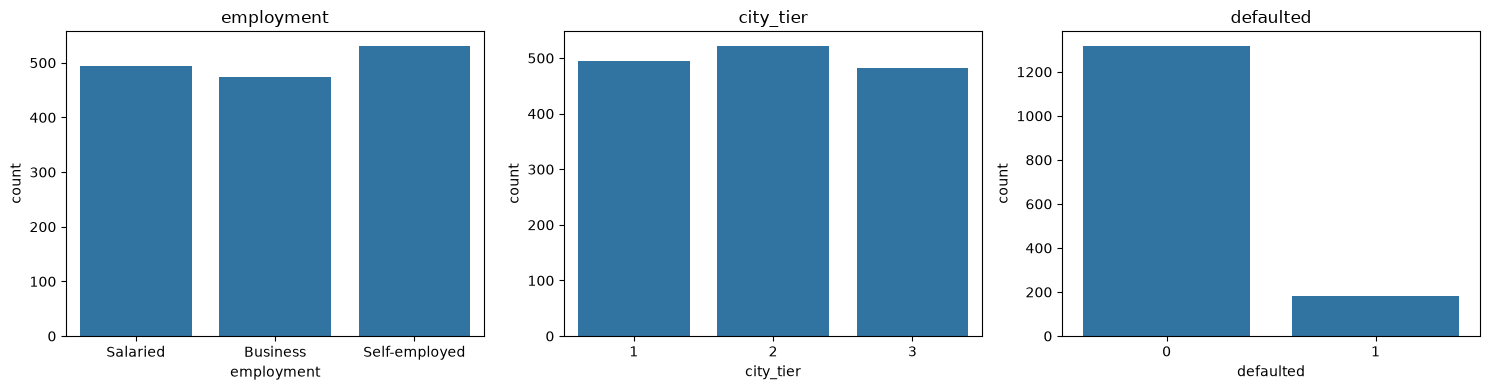

In [3]:
numeric_cols = ['age', 'monthly_income_inr', 'loan_amount_inr', 'tenure_months', 'credit_score', 'city_tier']
print(loans[numeric_cols].describe())

for col in ['employment', 'city_tier', 'defaulted']:
    print(loans[col].value_counts(normalize=True))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for ax, col in zip(axes, numeric_cols):
    ax.hist(loans[col], bins=15, edgecolor='black')
    ax.set_title(col)
plt.tight_layout()
fig.savefig('loan_numeric.png')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['employment', 'city_tier', 'defaulted']):
    sns.countplot(data=loans, x=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
fig.savefig('loan_categorical.png')
plt.show()

# Task 3

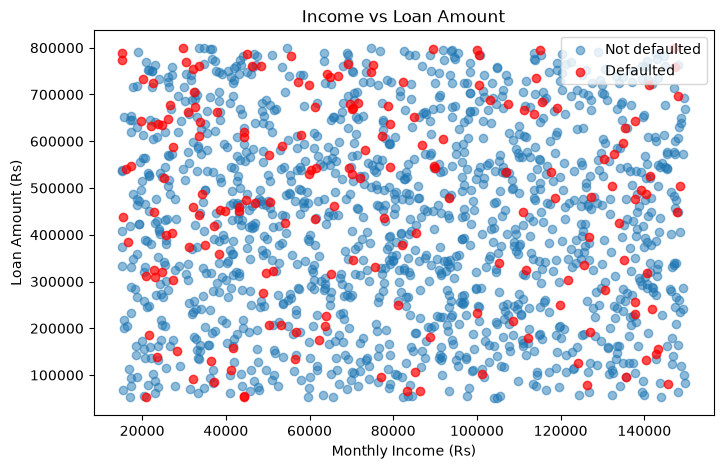

age                  -0.018844
monthly_income_inr   -0.068110
loan_amount_inr       0.078122
tenure_months         0.027034
city_tier             0.016326
credit_score         -0.152100
Name: defaulted, dtype: float64
employment
Business         0.118143
Salaried         0.119192
Self-employed    0.126177
Name: defaulted, dtype: float64
city_tier
1    0.125253
2    0.101533
3    0.138716
Name: defaulted, dtype: float64


In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(loans.loc[loans['defaulted'] == 0, 'monthly_income_inr'], loans.loc[loans['defaulted'] == 0, 'loan_amount_inr'], alpha=0.5, label='Not defaulted')
ax.scatter(loans.loc[loans['defaulted'] == 1, 'monthly_income_inr'], loans.loc[loans['defaulted'] == 1, 'loan_amount_inr'], alpha=0.7, color='red', label='Defaulted')
ax.set_title('Income vs Loan Amount')
ax.set_xlabel('Monthly Income (Rs)')
ax.set_ylabel('Loan Amount (Rs)')
ax.legend()
fig.savefig('loan_scatter.png')
plt.show()

print(loans.corr(numeric_only=True)['defaulted'].drop('defaulted'))

rate_employment = loans.groupby('employment')['defaulted'].mean()
rate_city = loans.groupby('city_tier')['defaulted'].mean()
print(rate_employment)
print(rate_city)

rate_city.index = ['Tier ' + str(i) for i in rate_city.index]
default_rates = pd.concat([rate_employment, rate_city]).rename('default_rate')
default_rates.to_csv('default_rates.csv', index_label='group')

# Task 4

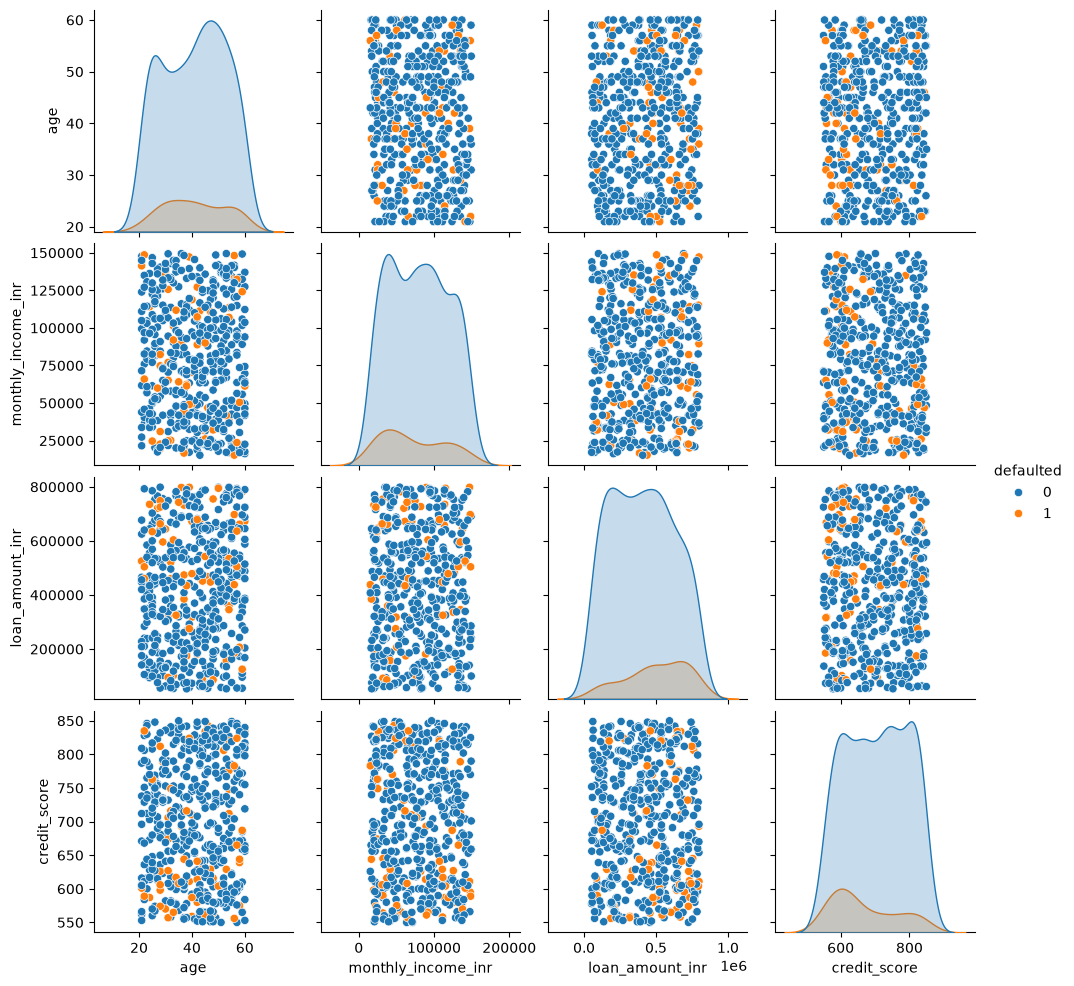

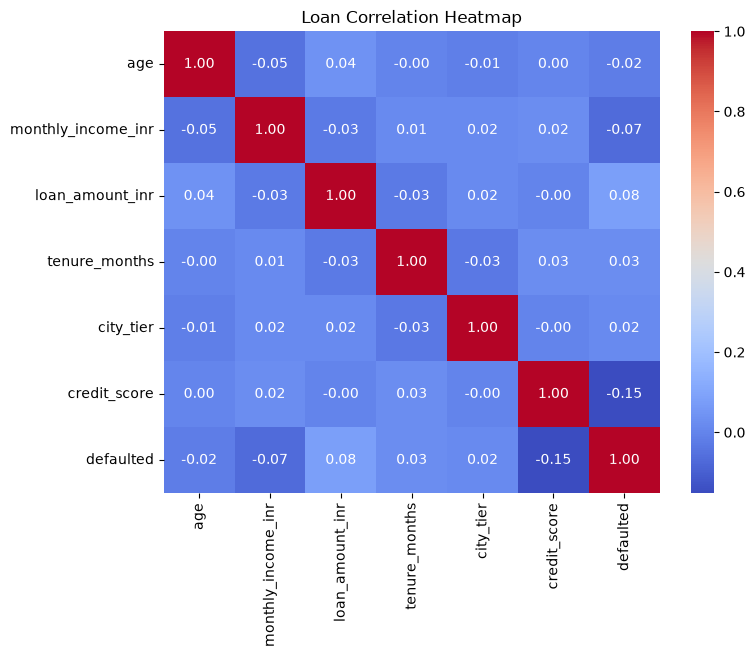

                                         finding  \
0                           Overall default rate   
1                Low credit score raises default   
2            Loans above 10x income default more   
3  Credit score is negatively related to default   
4  Employment type with the highest default rate   

                                   evidence  
0                     Default rate is 12.1%  
1   Below 650: 21.4% vs 650 and above: 7.4%  
2  Above 10x income: 19.6% vs others: 10.1%  
3                     Correlation is -0.152  
4                    Self-employed at 12.6%  


In [5]:
sample = loans.sample(500, random_state=42)
g = sns.pairplot(sample[['age', 'monthly_income_inr', 'loan_amount_inr', 'credit_score', 'defaulted']], hue='defaulted')
g.savefig('loan_pairplot.png')
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(loans.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
ax.set_title('Loan Correlation Heatmap')
fig.savefig('loan_heatmap.png')
plt.show()

overall_rate = loans['defaulted'].mean()
low_score_rate = loans.loc[loans['credit_score'] < 650, 'defaulted'].mean()
high_score_rate = loans.loc[loans['credit_score'] >= 650, 'defaulted'].mean()
big_loan_rate = loans.loc[loans['loan_amount_inr'] > 10 * loans['monthly_income_inr'], 'defaulted'].mean()
normal_loan_rate = loans.loc[loans['loan_amount_inr'] <= 10 * loans['monthly_income_inr'], 'defaulted'].mean()
score_corr = loans['credit_score'].corr(loans['defaulted'])
top_employment = rate_employment.idxmax()

eda_findings = pd.DataFrame({
    'finding': [
        'Overall default rate',
        'Low credit score raises default',
        'Loans above 10x income default more',
        'Credit score is negatively related to default',
        'Employment type with the highest default rate'
    ],
    'evidence': [
        'Default rate is ' + str(round(overall_rate * 100, 1)) + '%',
        'Below 650: ' + str(round(low_score_rate * 100, 1)) + '% vs 650 and above: ' + str(round(high_score_rate * 100, 1)) + '%',
        'Above 10x income: ' + str(round(big_loan_rate * 100, 1)) + '% vs others: ' + str(round(normal_loan_rate * 100, 1)) + '%',
        'Correlation is ' + str(round(score_corr, 3)),
        top_employment + ' at ' + str(round(rate_employment.max() * 100, 1)) + '%'
    ]
})

print(eda_findings)
eda_findings.to_csv('loan_eda_findings.csv', index=False)